<a href="https://colab.research.google.com/github/D-LukeSherman/ECGR-4105/blob/main/Homework5/Homework5_Problem2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [427]:
import torch
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [428]:
# Use the URL for the raw CSV data
url = 'https://raw.githubusercontent.com/D-LukeSherman/ECGR-4105/refs/heads/main/Homework4/Housing.csv'

dataset = pd.read_csv(url)

# Preprocessing

varlist = ['mainroad', 'guestroom', 'basement', 'hotwaterheating',
            'airconditioning', 'prefarea']

def binary_map(x):
    return x.map({'yes': 1, 'no': 0})

dataset[varlist] = dataset[varlist].apply(binary_map)

# Map furnishingstatus: furnished -> 2, semi-furnished -> 1, unfurnished -> 0
status_map = {'furnished': 2, 'semi-furnished': 1, 'unfurnished': 0}
dataset['furnishingstatus'] = dataset['furnishingstatus'].map(status_map)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
num_vars = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
            'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

dataset[num_vars] = scaler.fit_transform(dataset[num_vars])

# Separating out the features
x = dataset.iloc[:, [1, 2, 3, 4, 10]].values
# Separating out the target
y = dataset.iloc[:, 0].values

Xtrain, Xtest, ytrain, ytest = train_test_split(x, y, test_size = 0.2,
                                                random_state=42)

Xtrain

array([[ 0.3917898 ,  0.04727831,  1.42181174,  2.53202371,  0.35597563],
       [ 0.94525725,  0.04727831,  1.42181174, -0.92939666,  2.67940935],
       [-0.61552098, -1.30886273, -0.57018671, -0.92939666,  1.51769249],
       ...,
       [-0.30004453,  0.04727831,  1.42181174,  1.37821692,  0.35597563],
       [-0.51220705, -1.30886273, -0.57018671, -0.92939666, -0.80574124],
       [ 0.16117836,  0.04727831,  1.42181174,  2.53202371,  0.35597563]])

In [429]:
# In[2]:
t_u_train = torch.tensor(Xtrain, dtype=torch.float32)
t_c_train = torch.tensor(ytrain, dtype=torch.float32)

t_u_val = torch.tensor(Xtest, dtype=torch.float32)
t_c_val = torch.tensor(ytest, dtype=torch.float32)

t_u_train

tensor([[ 0.3918,  0.0473,  1.4218,  2.5320,  0.3560],
        [ 0.9453,  0.0473,  1.4218, -0.9294,  2.6794],
        [-0.6155, -1.3089, -0.5702, -0.9294,  1.5177],
        ...,
        [-0.3000,  0.0473,  1.4218,  1.3782,  0.3560],
        [-0.5122, -1.3089, -0.5702, -0.9294, -0.8057],
        [ 0.1612,  0.0473,  1.4218,  2.5320,  0.3560]])

In [430]:
def model(t_u, w, b):
    # Perform matrix-vector multiplication using the @ operator for linear regression
    return t_u @ w + b

In [431]:
def loss_fn(t_p, t_c):
  # Training on standard Mean Squared Error (MSE)
  squared_diffs = (t_p - t_c)**2
  return squared_diffs.mean()

In [432]:
# In[5]:
# Initialize 5 weights (one for each feature) and 1 scalar bias
w = torch.ones(5, requires_grad=True)
b = torch.zeros((), requires_grad=True)

In [433]:
# In[5]:
import torch.optim as optim
# dir(optim)

In [434]:
# In[9]:
def training_loop(n_epochs, optimizer, params, t_u_train, t_u_val, t_c_train, t_c_val):
  train_loss_history = []
  val_loss_history = []

  for epoch in range(1, n_epochs + 1):
    t_p_train = model(t_u_train, params[:-1], params[-1])
    loss_train = loss_fn(t_p_train, t_c_train)

    t_p_val = model(t_u_val, params[:-1], params[-1])
    loss_val = loss_fn(t_p_val, t_c_val)

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    if epoch == 1 or epoch % 500 == 0:
      # Calculate and store Root Mean Squared Error (RMSE) for tracking
      train_loss_history.append(torch.sqrt(loss_train).item())
      val_loss_history.append(torch.sqrt(loss_val).item())

  return params, train_loss_history, val_loss_history

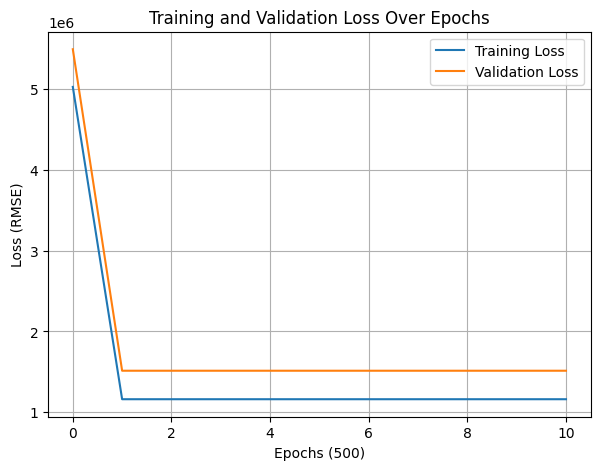

In [435]:
# Train the model using the properly normalized inputs and store loss history
import matplotlib.pyplot as plt

params = torch.tensor([1.0, 1.0, 1.0, 1.0, 1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params], lr=1e-1)

params, train_loss, val_loss = training_loop(
  n_epochs = 5000,
  optimizer = optimizer,
  params = params,
  t_u_train = t_u_train,
  t_u_val = t_u_val,
  t_c_train = t_c_train,
  t_c_val = t_c_val
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss (RMSE)')
plt.title('Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [436]:
val_loss[10]

1514173.625

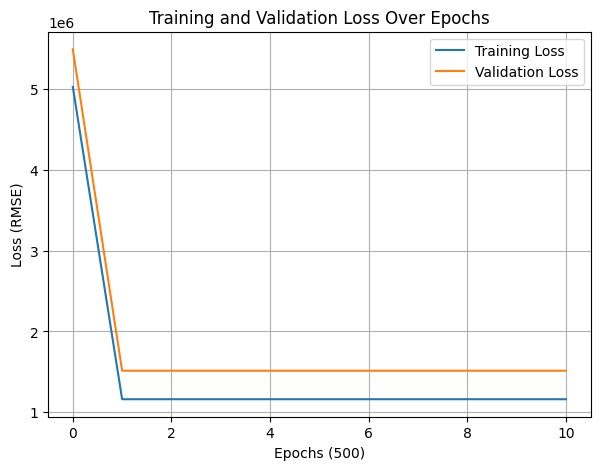

In [437]:
params = torch.tensor([1.0, 1.0, 1.0, 1.0, 1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params], lr=1e-2)

params, train_loss, val_loss = training_loop(
  n_epochs = 5000,
  optimizer = optimizer,
  params = params,
  t_u_train = t_u_train,
  t_u_val = t_u_val,
  t_c_train = t_c_train,
  t_c_val = t_c_val
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss (RMSE)')
plt.title('Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [438]:
val_loss[10]

1514174.5

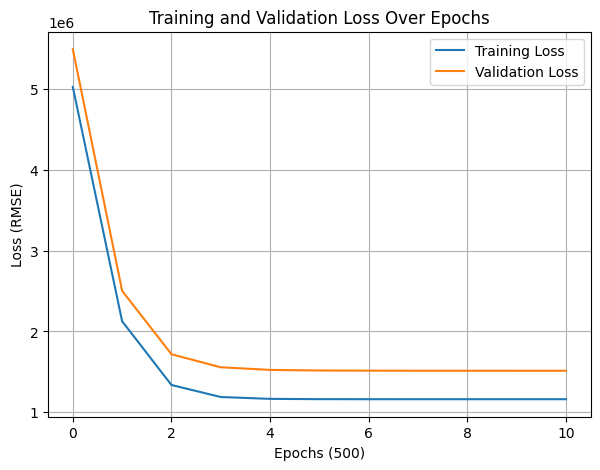

In [439]:
params = torch.tensor([1.0, 1.0, 1.0, 1.0, 1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params], lr=1e-3)

params, train_loss, val_loss = training_loop(
  n_epochs = 5000,
  optimizer = optimizer,
  params = params,
  t_u_train = t_u_train,
  t_u_val = t_u_val,
  t_c_train = t_c_train,
  t_c_val = t_c_val
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss (RMSE)')
plt.title('Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

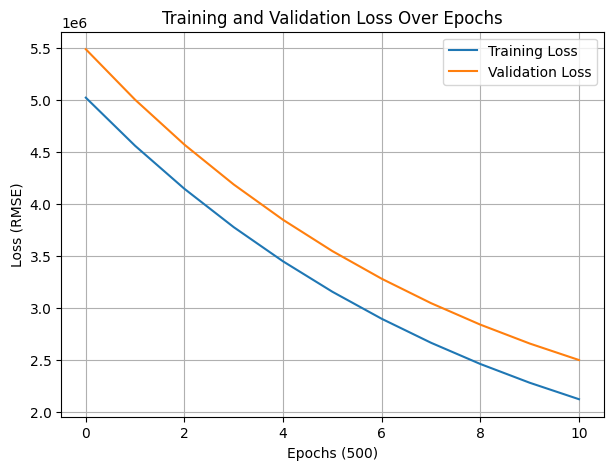

In [440]:
params = torch.tensor([1.0, 1.0, 1.0, 1.0, 1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params], lr=1e-4)

params, train_loss, val_loss = training_loop(
  n_epochs = 5000,
  optimizer = optimizer,
  params = params,
  t_u_train = t_u_train,
  t_u_val = t_u_val,
  t_c_train = t_c_train,
  t_c_val = t_c_val
)

# Graphing training and validation losses
plt.figure(figsize=(7, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs (500)')
plt.ylabel('Loss (RMSE)')
plt.title('Training and Validation Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()